># **Handling Missing Values**

>## **Univariate Imputer**

### **Complete Case Analysis(CCA)**

In [253]:
import pandas as pd
import numpy as np

In [254]:
data = pd.read_csv(r"C:\Users\LENOVO\Downloads\archive (1)\synthetic_dataset.csv")

In [255]:
data.head()

,Category,Price,Rating,Stock,Discount
0,NaN,5548.0,1.870322,NaN,0.0
1,NaN,3045.0,4.757798,NaN,38.0
2,NaN,4004.0,NaN,In Stock,0.0
3,NaN,4808.0,1.492085,NaN,33.0
4,NaN,1817.0,NaN,Out of Stock,23.0


In [256]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4362 entries, 0 to 4361
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Category  1614 non-null   str    
 1   Price     4188 non-null   float64
 2   Rating    2312 non-null   float64
 3   Stock     3010 non-null   str    
 4   Discount  3970 non-null   float64
dtypes: float64(3), str(2)
memory usage: 202.5 KB


In [257]:
data.isnull().mean()*100

Category    62.998624
Price        3.988996
Rating      46.996790
Stock       30.994956
Discount     8.986703
dtype: float64

In [258]:
cols = [col for col in data.columns if data[col].isnull().mean() < 0.05 and data[col].isna().mean() > 0]
cols

['Price']

In [259]:
len(data['Price'].dropna())/len(data)

0.9601100412654745

In [260]:
new_df = data[cols].dropna()

In [261]:
data.shape,new_df.shape

((4362, 5), (4188, 1))

In [262]:
import matplotlib.pyplot as plt

<Axes: >

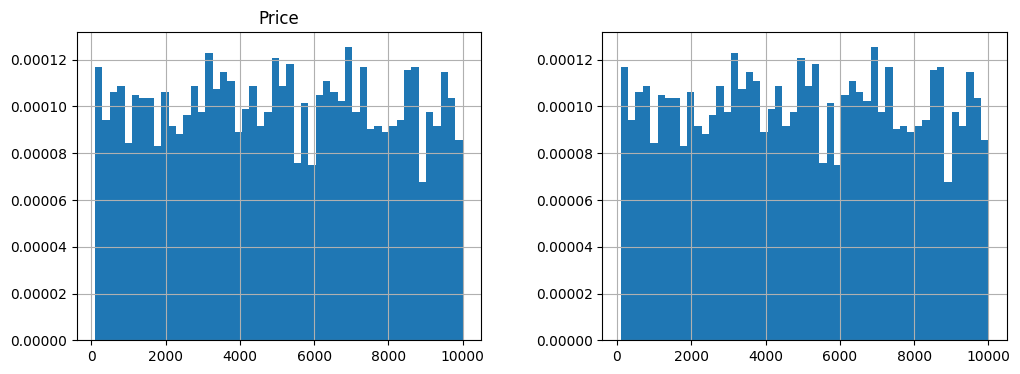

In [263]:
fig , (ax1, ax2) = plt.subplots(ncols=2)
new_df.hist(bins=50,density = True,figsize=(12,4),ax=ax1)
data['Price'].hist(bins=50,density = True,figsize=(12,4),ax=ax2)

>## **Handling Numerical Data**

>## **Mean/Median Imputation**

In [264]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [265]:
data.head(3)

,Category,Price,Rating,Stock,Discount
0,NaN,5548.0,1.870322,NaN,0.0
1,NaN,3045.0,4.757798,NaN,38.0
2,NaN,4004.0,NaN,In Stock,0.0


In [266]:
temp = data

In [267]:
temp['Price_mean'] = data['Price'].fillna(data['Price'].mean())
temp['Price_median'] = data['Price'].fillna(data['Price'].median())

>## **Using Mean**

In [268]:
titanic = pd.read_csv(r"C:\Users\LENOVO\Downloads\titanic.csv",usecols=['Age','Survived','Fare'])
temp = titanic

In [269]:
titanic['Age_Mean'] = titanic['Age'].fillna(titanic['Age'].mean())
titanic['Age_Median'] = titanic['Age'].fillna(titanic['Age'].median())

Text(0.5, 1.0, 'Age Imputation(Median)')

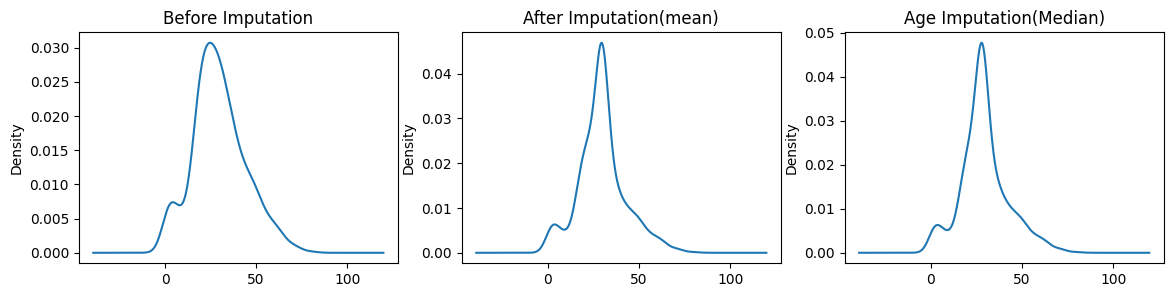

In [270]:
fig , (ax1,ax2,ax3) = plt.subplots(ncols=3,figsize = (14,3))
fig = titanic['Age_Mean'].plot(kind='kde',ax= ax2)
ax1.set_title('Before Imputation')
fig = titanic['Age'].plot(kind='kde',ax = ax1)
ax2.set_title('After Imputation(mean)')
fig = titanic['Age_Median'].plot(kind='kde',ax=ax3)
ax3.set_title('Age Imputation(Median)')

**`After Imputation Distribution is Change`**
<br>variance is Srink

<Axes: >

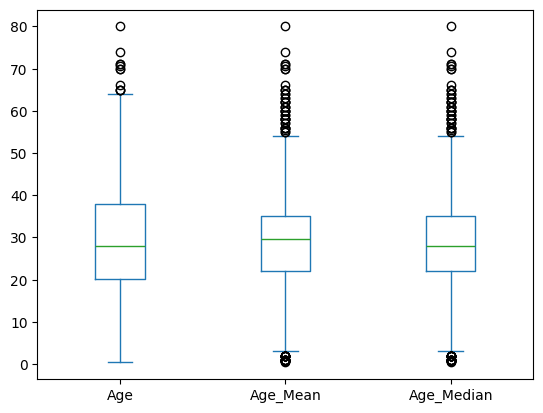

In [271]:
titanic[['Age','Age_Mean','Age_Median']].plot(kind='box')

In [272]:
trf = ColumnTransformer(transformers=[
    ('impute_mean',SimpleImputer(strategy='mean'),['Price']), # mean 
    ('impute_median',SimpleImputer(strategy='median'),['Discount','Rating']), # median
    ('impute_mode',SimpleImputer(strategy='most_frequent'),['Stock','Category']) # mode
])

In [273]:
trf.fit(data)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('impute_mean', ...), ('impute_median', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and `

In [274]:
trf.named_transformers_['impute_mean'].statistics_

array([5016.97063037])

In [275]:
trf.named_transformers_['impute_median'].statistics_

array([25.        ,  3.08206005])

In [276]:
trf.named_transformers_['impute_mode'].statistics_

array(['In Stock', 'C'], dtype=object)

>## **Arbitarry Value Imputation**
- Not MCAN

In [277]:
data['Category_new']=data['Category'].fillna('missing')

In [278]:
data.head()

,Category,Price,Rating,Stock,Discount,Price_mean,Price_median,Category_new
0,NaN,5548.0,1.870322,NaN,0.0,5548.0,5548.0,missing
1,NaN,3045.0,4.757798,NaN,38.0,3045.0,3045.0,missing
2,NaN,4004.0,NaN,In Stock,0.0,4004.0,4004.0,missing
3,NaN,4808.0,1.492085,NaN,33.0,4808.0,4808.0,missing
4,NaN,1817.0,NaN,Out of Stock,23.0,1817.0,1817.0,missing


In [279]:
trf1 = ColumnTransformer(transformers=[
    ('impute1',SimpleImputer(strategy='constant',fill_value='missing'),['Category','Stock'])])

In [280]:
trf1.fit(data)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('impute1', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{featur

>## **End Of Distribution Imputation**
- same as arbitarry but fill with end of distribution <br>
- if data is normal (`mean +- 3std`)<br>
- if data is skew (IQR proximaty rule, `Q1 - 1.5*IQR` or `Q3 + 1.5*IQR`)

># **Categorrical value**

In [281]:
data.head()

,Category,Price,Rating,Stock,Discount,Price_mean,Price_median,Category_new
0,NaN,5548.0,1.870322,NaN,0.0,5548.0,5548.0,missing
1,NaN,3045.0,4.757798,NaN,38.0,3045.0,3045.0,missing
2,NaN,4004.0,NaN,In Stock,0.0,4004.0,4004.0,missing
3,NaN,4808.0,1.492085,NaN,33.0,4808.0,4808.0,missing
4,NaN,1817.0,NaN,Out of Stock,23.0,1817.0,1817.0,missing


>## **Random Value Imputation**

- Randomly impute values from same column
- keep distribution same

>## **Missing Indicater**

In [282]:
from sklearn.impute import MissingIndicator

In [283]:
dt = {'Marks':[22,38,71,np.nan,56,np.nan]}
df = pd.DataFrame(dt)
df

,Marks
0,22.0
1,38.0
2,71.0
3,NaN
4,56.0
5,NaN


In [284]:
indicator = MissingIndicator(missing_values=np.nan)
df['Marks_nan'] = indicator.fit_transform(df)

In [285]:
df

,Marks,Marks_nan
0,22.0,False
1,38.0,False
2,71.0,False
3,NaN,True
4,56.0,False
5,NaN,True


In [286]:
from sklearn.impute import SimpleImputer
s1 = SimpleImputer(add_indicator=True)
s1.fit_transform(df)

array([[22.  ,  0.  ,  0.  ],
       [38.  ,  0.  ,  0.  ],
       [71.  ,  0.  ,  0.  ],
       [46.75,  1.  ,  1.  ],
       [56.  ,  0.  ,  0.  ],
       [46.75,  1.  ,  1.  ]])

>## **Automatically Select Value For Imputation**

In [287]:
data = pd.read_csv(r"C:\Users\LENOVO\Downloads\titanic.csv",usecols=['Survived','Embarked','Age','Sex','Pclass','Fare'])

In [288]:
data.head()

,Survived,Pclass,Sex,Age,Fare,Embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


In [289]:
x = data.drop(columns=['Survived'])
y = data['Survived']

In [290]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV 

In [291]:
x_train ,x_test, y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [292]:
num_features = ['Fare','Age']
cat_features = ['Embarked','Sex']

num_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median')),
    ('sacler',StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('ohe',OneHotEncoder(handle_unknown='ignore'))
])

In [293]:
preprocessor = ColumnTransformer(transformers=[
    ('num',num_transformer,num_features),
    ('cat',cat_transformer,cat_features)
])

In [294]:
pipe = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('Classifier',LogisticRegression())
])

In [295]:
pipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('Classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [296]:
preprocessor.get_feature_names_out()

array(['num__Fare', 'num__Age', 'cat__Embarked_C', 'cat__Embarked_Q',
       'cat__Embarked_S', 'cat__Sex_female', 'cat__Sex_male'],
      dtype=object)

In [302]:
param_grid = {
    'preprocessor__num__imputer__strategy' : ['mean','median'],
    'preprocessor__cat__imputer__strategy' : ['most_frequent','constant'],
    'Classifier__C': [0.1,1.0,10,100]
}

In [303]:
grid_search = GridSearchCV(pipe,param_grid=param_grid,cv=10)

In [304]:
grid_search.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Classifier__C': [0.1, 1.0, ...], 'preprocessor__cat__imputer__strategy': ['most_frequent', 'constant'], 'preprocessor__num__imputer__strategy': ['mean', 'median']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the

In [305]:
print('best params')
grid_search.best_params_

best params


{'Classifier__C': 0.1,
 'preprocessor__cat__imputer__strategy': 'most_frequent',
 'preprocessor__num__imputer__strategy': 'mean'}

In [300]:
pipe.named_steps.keys()

dict_keys(['preprocessor', 'Classifier'])

In [301]:
pipe.named_steps['preprocessor'].named_transformers_['num'].named_steps.keys()

dict_keys(['imputer', 'sacler'])

In [311]:
print(f' Internal Cross_Val Score: {grid_search.best_score_*100:.2f}%')

 Internal Cross_Val Score: 78.37%


># **Multivariate Imputer**

># **KNN Imputer**